# PS1 — New Jersey Youth Football and State Government Support

## 1. Introduction

In PS0, I mapped 264 community youth football organizations across New Jersey.

For PS1, I want to explore how these organizations relate to programs and resources offered by three New Jersey state departments:

- Department of Children and Families (DCF)
- Department of Community Affairs (DCA)
- Department of State (DOS)

My larger research focuses on the proposed New Jersey Youth and Amateur Sports Association (NJYASA). I want to understand how NJYASA could potentially help these departments connect with youth sports organizations and the families they serve.

I will begin by examining NJ4S universal support programs offered through DCF. These programs focus on prevention, mental health awareness, and supporting children and families.

I will use geographic data to compare existing government programs with documented youth football locations and identify possible opportunities for future partnerships.

In [32]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [33]:
# Load New Jersey's county boundaries

url = (
    "https://services2.arcgis.com/XVOqAjTOJ5P6ngMu/arcgis/rest/services/"
    "NJ_Counties_3424/FeatureServer/0/query"
    "?where=1%3D1&outFields=*&returnGeometry=true&outSR=4326&f=geojson"
)

counties = gpd.read_file(url)

print("Number of counties:", len(counties))

Number of counties: 21


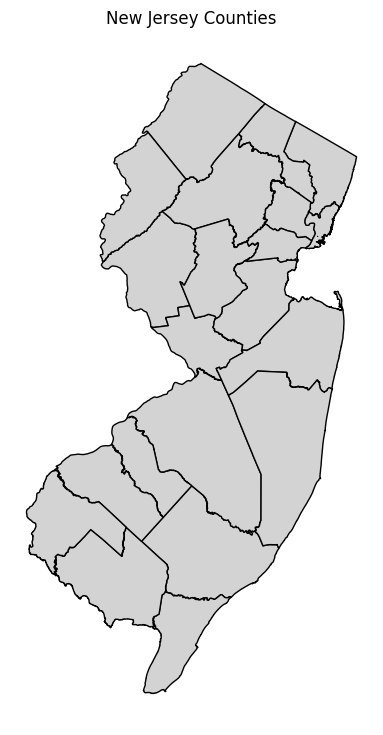

In [34]:
fig, ax = plt.subplots(figsize=(7, 9))

counties.to_crs(epsg=3424).plot(
    ax=ax,
    color="lightgray",
    edgecolor="black"
)

ax.set_title("New Jersey Counties")
ax.axis("off")

plt.show()

In [35]:
# Load youth football organizations from PS0

football_url = (
    "https://raw.githubusercontent.com/Dunk0725/GIS-26/"
    "NJ-Youth-Football-GIS/"
    "PS0_NJ_Youth_Football_Locations_2026.csv"
)

football = pd.read_csv(football_url)

print("Total organizations:", len(football))

# Exclude P181, pending organization verification
football = football[football["Program_ID"] != "P181"].copy()

print("Organizations included:", len(football))

Total organizations: 265
Organizations included: 264


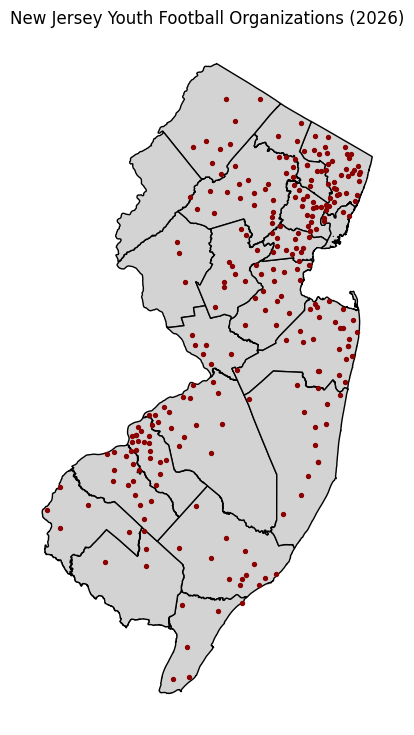

In [36]:
# Turn football locations into map points
football_points = gpd.GeoDataFrame(
    football,
    geometry=gpd.points_from_xy(
        football["Longitude"],
        football["Latitude"]
    ),
    crs="EPSG:4326"
)

# Create the map
fig, ax = plt.subplots(figsize=(7, 9))

counties.to_crs(epsg=3424).plot(
    ax=ax,
    color="lightgray",
    edgecolor="black"
)

football_points.to_crs(epsg=3424).plot(
    ax=ax,
    color="darkred",
    markersize=8
)

ax.set_title("New Jersey Youth Football Organizations (2026)")
ax.axis("off")

plt.show()

## 2. Department of Children and Families — NJ4S Universal Supports

The New Jersey Statewide Student Support Services (NJ4S) program offers Tier 1 universal prevention services to students and families. These include workshops, presentations, and activities focused on mental health and well-being.

NJ4S operates through 15 regional hubs covering New Jersey's 21 counties.

For this map, I will compare NJ4S Tier 1 attendance by regional hub from August 2023 through August 2024 with my documented youth football locations from 2026.

**Research Question:** How does NJ4S universal support attendance vary across New Jersey, and where might youth football organizations offer additional opportunities for community outreach?

The attendance figures count participation in services, not necessarily unique individuals. Some hubs serve multiple counties.

**Source:** New Jersey Department of Children and Families, *NJ4S Evaluation: Preliminary Phase 1 Findings*, October 1, 2024, page 10.

https://www.nj.gov/dcf/documents/ARE-Presentation-Advisory-Taskforce_10-1-24.pdf

In [37]:
# Approximate NJ4S Tier 1 attendance, 2023–2024

attendance = [
    ["Atlantic, Cape May", 23000],
    ["Bergen", 2800],
    ["Burlington", 4900],
    ["Camden", 17000],
    ["Essex", 18000],
    ["Gloucester, Cumberland, Salem", 17000],
    ["Hudson", 13000],
    ["Mercer", 8900],
    ["Middlesex", 9800],
    ["Monmouth", 7500],
    ["Morris, Sussex", 16000],
    ["Ocean", 14000],
    ["Passaic", 17000],
    ["Somerset, Hunterdon, Warren", 21000],
    ["Union", 5500]
]

nj4s = pd.DataFrame(
    attendance,
    columns=["Region", "Approx_Attendance"]
)

print("NJ4S regions:", len(nj4s))
display(nj4s)

NJ4S regions: 15


,Region,Approx_Attendance
0,"Atlantic, Cape May",23000
1,Bergen,2800
2,Burlington,4900
3,Camden,17000
4,Essex,18000
5,"Gloucester, Cumberland, Salem",17000
6,Hudson,13000
7,Mercer,8900
8,Middlesex,9800
9,Monmouth,7500


In [38]:
# Check the county data columns

print(counties.columns.tolist())

['OBJECTID', 'COUNTY', 'COUNTY_LABEL', 'CO', 'GNIS_NAME', 'GNIS', 'FIPSSTCO', 'FIPSCO', 'ACRES', 'SQ_MILES', 'POP2020', 'POP2010', 'POP2000', 'POP1990', 'POP1980', 'POPDEN2020', 'POPDEN2010', 'POPDEN2000', 'POPDEN1990', 'POPDEN1980', 'REGION', 'Shape__Area', 'Shape__Length', 'geometry']


In [39]:
# View the first five county names

display(counties[["COUNTY", "COUNTY_LABEL", "GNIS_NAME"]].head())

,COUNTY,COUNTY_LABEL,GNIS_NAME
0,ATLANTIC,Atlantic County,County of Atlantic
1,BERGEN,Bergen County,County of Bergen
2,BURLINGTON,Burlington County,County of Burlington
3,CAMDEN,Camden County,County of Camden
4,CAPE MAY,Cape May County,County of Cape May


In [40]:
# Match each county to its NJ4S region

county_to_region = {}

for region in nj4s["Region"]:
    for county in region.split(", "):
        county_to_region[county.upper()] = region

counties["Region"] = counties["COUNTY"].map(county_to_region)

print("Counties matched:", counties["Region"].notna().sum())
print("NJ4S regions:", counties["Region"].nunique())

Counties matched: 21
NJ4S regions: 15


In [41]:
# Join NJ4S attendance to New Jersey counties

nj4s_counties = counties.merge(
    nj4s,
    on="Region",
    how="left"
)

print("Counties with attendance:",
      nj4s_counties["Approx_Attendance"].notna().sum())

display(
    nj4s_counties[
        ["COUNTY", "Region", "Approx_Attendance"]
    ].head()
)

Counties with attendance: 21


,COUNTY,Region,Approx_Attendance
0,ATLANTIC,"Atlantic, Cape May",23000
1,BERGEN,Bergen,2800
2,BURLINGTON,Burlington,4900
3,CAMDEN,Camden,17000
4,CAPE MAY,"Atlantic, Cape May",23000


In [42]:
# Combine counties into their NJ4S regions

nj4s_regions = nj4s_counties.dissolve(
    by="Region",
    aggfunc={"Approx_Attendance": "first"}
).reset_index()

print("NJ4S regions ready to map:", len(nj4s_regions))

display(nj4s_regions[["Region", "Approx_Attendance"]])

NJ4S regions ready to map: 15


,Region,Approx_Attendance
0,"Atlantic, Cape May",23000
1,Bergen,2800
2,Burlington,4900
3,Camden,17000
4,Essex,18000
5,"Gloucester, Cumberland, Salem",17000
6,Hudson,13000
7,Mercer,8900
8,Middlesex,9800
9,Monmouth,7500


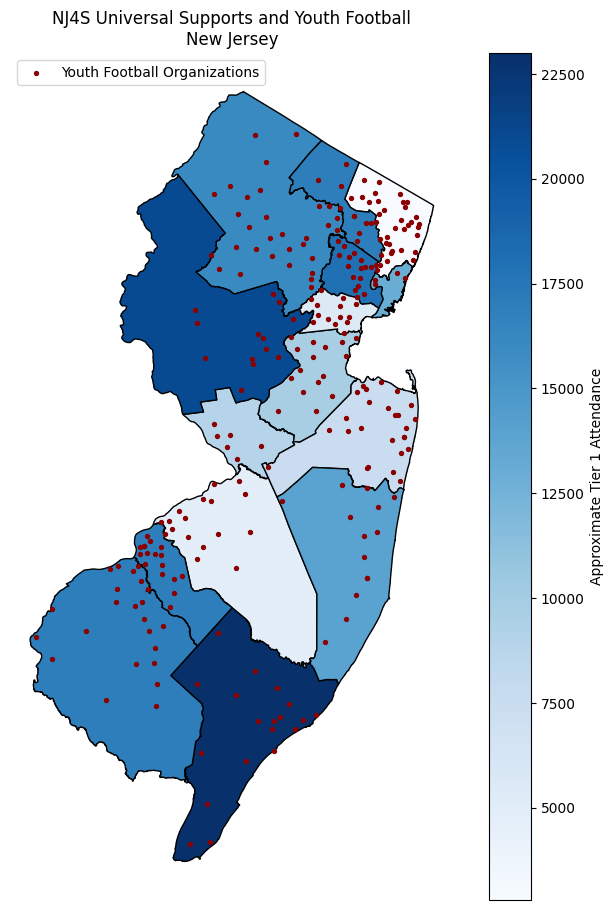

In [43]:
# Map NJ4S attendance and youth football locations

fig, ax = plt.subplots(figsize=(9, 11))

nj4s_regions.to_crs(epsg=3424).plot(
    column="Approx_Attendance",
    cmap="Blues",
    legend=True,
    edgecolor="black",
    ax=ax,
    legend_kwds={"label": "Approximate Tier 1 Attendance"}
)

football_points.to_crs(epsg=3424).plot(
    ax=ax,
    color="darkred",
    markersize=8,
    label="Youth Football Organizations"
)

ax.set_title("NJ4S Universal Supports and Youth Football\nNew Jersey")
ax.legend(loc="upper left")
ax.axis("off")

plt.show()

## 3. Results — NJ4S Universal Supports

The map shows differences in NJ4S Tier 1 attendance across New Jersey's 15 service regions.

Some regions reported higher attendance than others. For example, Atlantic and Cape May reported approximately 23,000 attendances, while Bergen reported approximately 2,800.

The red dots show that community youth football organizations are located throughout these service regions.

This suggests that youth football organizations could be potential community partners for sharing information about NJ4S prevention programs with children and families.

However, the map does not show whether football organizations currently participate in NJ4S or whether families have difficulty accessing services.

The attendance figures are regional totals, not individual county totals or counts of unique people. They also come from an earlier period than the 2026 football data.

**Connection to NJYASA:** A future statewide youth sports association could explore partnerships with DCF to help local organizations promote available Tier 1 programs and resources.

## 4. Department of Community Affairs — Recreation and Youth Football

The New Jersey Department of Community Affairs (DCA) supports local governments and community recreation through programs such as the Local Recreation Improvement Grant (LRIG).

These grants help improve public recreational facilities, including parks, athletic fields, playgrounds, and community centers.

For this part of my research, I want to examine how recreation improvement funding was distributed across New Jersey counties in 2026.

I also want to understand the difference between youth football organizations operated by municipal recreation departments and those operated independently, including nonprofit organizations.

**Research Question:** How does DCA recreation improvement funding vary across New Jersey, and how could NJYASA help improve coordination between municipal governments and independent youth football organizations?

I will compare county-level DCA recreation grant awards with my documented youth football locations.

The grant data does not tell us whether a football organization received funding or whether it operates through a municipality. Those questions require separate research.

**Data Source:** New Jersey Department of Community Affairs, FY2026 Local Recreation Improvement Grant Awards.

https://www.nj.gov/dca/dlgs/programs/lriggrants.shtml

In [44]:

# Read the official DCA grant awards PDF
!pip -q install pdfplumber

import io
import re
import requests
import pdfplumber

dca_url = (
    "https://www.nj.gov/dca/dlgs/programs/lrig_docs/"
    "2026%20LRIG/FY2026_LRIG_Grant_Awards_Listing.pdf"
)

response = requests.get(dca_url, timeout=30)
response.raise_for_status()

# Find the county and award amount in each PDF row
county_names = "|".join(
    re.escape(name.title()) for name in counties["COUNTY"]
)
pattern = re.compile(
    rf"^(.+?)\s+({county_names})\s+([\d,]+)$"
)

records = []

with pdfplumber.open(io.BytesIO(response.content)) as pdf:
    for page in pdf.pages:
        for line in page.extract_text().splitlines():
            match = pattern.match(line.strip())
            if match:
                records.append([
                    match.group(1),
                    match.group(2).upper(),
                    int(match.group(3).replace(",", ""))
                ])

dca_grants = pd.DataFrame(
    records,
    columns=["Recipient", "COUNTY", "Award_Amount"]
)

print("Awards found:", len(dca_grants))
print("Total awarded: $", f"{dca_grants['Award_Amount'].sum():,}", sep="")
display(dca_grants.head())


Awards found: 154
Total awarded: $9,918,449


,Recipient,COUNTY,Award_Amount
0,Allendale Borough,BERGEN,45000
1,Allenhurst Borough,MONMOUTH,64200
2,Andover Regional School District,SUSSEX,69700
3,Andover Township,SUSSEX,66200
4,Asbury Park Public Schools,MONMOUTH,65700


In [45]:
# Calculate total DCA recreation funding by county

dca_county_totals = (
    dca_grants.groupby("COUNTY", as_index=False)["Award_Amount"]
    .sum()
)

print("Counties with grants:", len(dca_county_totals))

print("Total funding: $",
      f"{dca_county_totals['Award_Amount'].sum():,}",
      sep="")

display(dca_county_totals)

Counties with grants: 21
Total funding: $9,918,449


,COUNTY,Award_Amount
0,ATLANTIC,467400
1,BERGEN,1189400
2,BURLINGTON,576100
3,CAMDEN,329500
4,CAPE MAY,198100
5,CUMBERLAND,328487
6,ESSEX,434700
7,GLOUCESTER,500400
8,HUDSON,69200
9,HUNTERDON,313300


In [46]:
# Join DCA funding totals to New Jersey counties

dca_map = counties.merge(
    dca_county_totals,
    on="COUNTY",
    how="left"
)

print("Counties matched:",
      dca_map["Award_Amount"].notna().sum())

print("Total funding: $",
      f"{dca_map['Award_Amount'].sum():,}",
      sep="")

display(dca_map[["COUNTY", "Award_Amount"]].head())

Counties matched: 21
Total funding: $9,918,449


,COUNTY,Award_Amount
0,ATLANTIC,467400
1,BERGEN,1189400
2,BURLINGTON,576100
3,CAMDEN,329500
4,CAPE MAY,198100


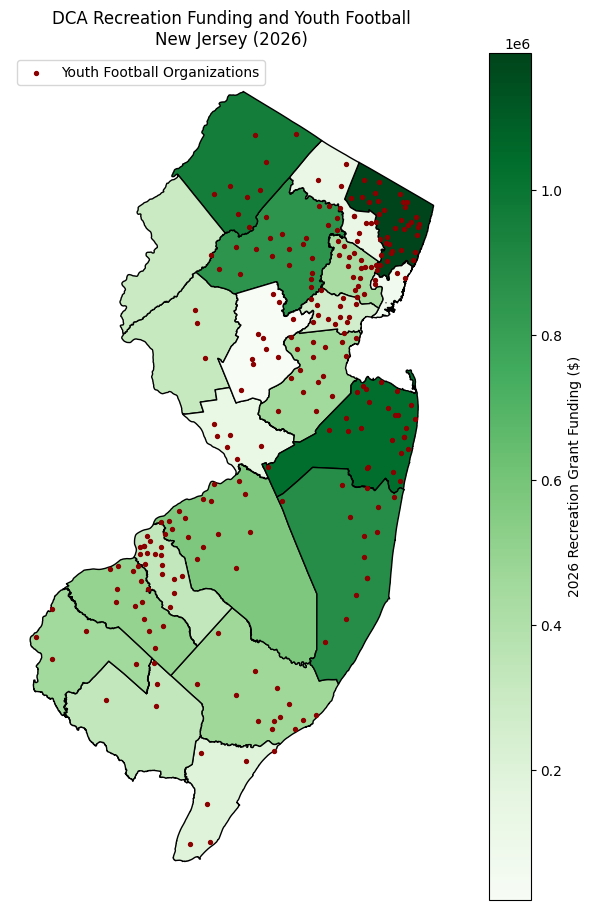

In [47]:

# Map DCA recreation funding and youth football locations

fig, ax = plt.subplots(figsize=(9, 11))

dca_map.to_crs(epsg=3424).plot(
    column="Award_Amount",
    cmap="Greens",
    legend=True,
    edgecolor="black",
    ax=ax,
    legend_kwds={"label": "2026 Recreation Grant Funding ($)"}
)

football_points.to_crs(epsg=3424).plot(
    ax=ax,
    color="darkred",
    markersize=8,
    label="Youth Football Organizations"
)

ax.set_title("DCA Recreation Funding and Youth Football\nNew Jersey (2026)")
ax.legend(loc="upper left")
ax.axis("off")

plt.show()


## 5. Results — DCA Recreation Funding

The map shows how New Jersey's 2026 Local Recreation Improvement Grant funding was distributed across the state's 21 counties.

DCA awarded approximately $9.9 million in recreation improvement grants.

Some counties received considerably more funding than others. Bergen County received approximately $1.19 million, while Somerset County received approximately $21,000.

The red dots show the locations of documented community youth football organizations.

Although these organizations operate throughout New Jersey, the map does not show whether they directly benefited from DCA-funded improvements.

**Connection to NJYASA:** A statewide youth sports association could potentially help local sports organizations work with municipal governments to identify recreational facility needs, improve communication, and coordinate access to public athletic fields.

An additional part of my research will examine how many youth football organizations are operated by municipal recreation departments compared with independently operated organizations, including nonprofits. Their operating structures must be verified before drawing conclusions.

## 6. Department of State — Volunteer Support and Recognition

The New Jersey Department of State supports volunteerism through its Governor's Office of Volunteerism and other service programs.

Community youth football organizations depend on volunteers, including coaches, team managers, and other community members who donate their time.

For this part of my research, I want to examine the volunteer-support organizations listed by the Department of State across New Jersey's counties.

**Research Question:** How are volunteer-support resources distributed across New Jersey, and how could NJYASA help connect youth football organizations with volunteer recruitment, training, and recognition opportunities?

I will compare the Department of State's county volunteer-center directory with my documented youth football locations.

The map will show the number of volunteer-support organizations listed for each county. It will not measure the number of volunteer coaches, their hours of service, or whether they have received recognition.

I also want to eventually investigate which youth football organizations have verified nonprofit status and whether they are aware of state nonprofit resources.

**Data Source:** New Jersey Department of State, Volunteer Centers of New Jersey.

https://www.nj.gov/state/volunteer-centers.shtml

In [48]:

# Volunteer center listings by county
# Source: NJ Department of State, August 2026

volunteer_counts = {
    "ATLANTIC": 2,
    "BERGEN": 1,
    "BURLINGTON": 2,
    "CAMDEN": 1,
    "CAPE MAY": 2,
    "CUMBERLAND": 2,
    "ESSEX": 1,
    "GLOUCESTER": 1,
    "HUDSON": 2,
    "HUNTERDON": 1,
    "MERCER": 1,
    "MIDDLESEX": 1,
    "MONMOUTH": 1,
    "MORRIS": 1,
    "OCEAN": 1,
    "PASSAIC": 1,
    "SALEM": 1,
    "SOMERSET": 1,
    "SUSSEX": 1,
    "UNION": 1,
    "WARREN": 1
}

volunteers = pd.DataFrame(
    volunteer_counts.items(),
    columns=["COUNTY", "Volunteer_Listings"]
)

print("Counties:", len(volunteers))
print("County directory listings:", volunteers["Volunteer_Listings"].sum())

display(volunteers)


Counties: 21
County directory listings: 26


,COUNTY,Volunteer_Listings
0,ATLANTIC,2
1,BERGEN,1
2,BURLINGTON,2
3,CAMDEN,1
4,CAPE MAY,2
5,CUMBERLAND,2
6,ESSEX,1
7,GLOUCESTER,1
8,HUDSON,2
9,HUNTERDON,1


In [49]:
# Join volunteer listings to New Jersey counties

dos_map = counties.merge(
    volunteers,
    on="COUNTY",
    how="left"
)

print("Counties matched:",
      dos_map["Volunteer_Listings"].notna().sum())

print("Total directory listings:",
      dos_map["Volunteer_Listings"].sum())

display(dos_map[["COUNTY", "Volunteer_Listings"]].head())

Counties matched: 21
Total directory listings: 26


,COUNTY,Volunteer_Listings
0,ATLANTIC,2
1,BERGEN,1
2,BURLINGTON,2
3,CAMDEN,1
4,CAPE MAY,2


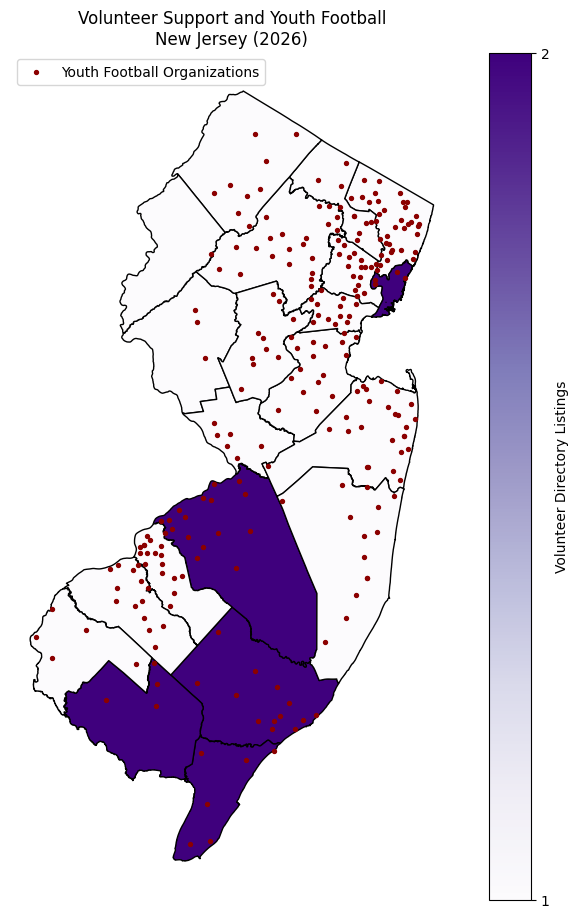

In [50]:

# Map volunteer support listings and youth football locations

fig, ax = plt.subplots(figsize=(9, 11))

dos_map.to_crs(epsg=3424).plot(
    column="Volunteer_Listings",
    cmap="Purples",
    legend=True,
    edgecolor="black",
    ax=ax,
    vmin=1,
    vmax=2,
    legend_kwds={
        "label": "Volunteer Directory Listings",
        "ticks": [1, 2]
    }
)

football_points.to_crs(epsg=3424).plot(
    ax=ax,
    color="darkred",
    markersize=8,
    label="Youth Football Organizations"
)

ax.set_title(
    "Volunteer Support and Youth Football\nNew Jersey (2026)"
)

ax.legend(loc="upper left")
ax.axis("off")

plt.show()


## 7. Results — Department of State Volunteer Support

The map shows volunteer-support organizations listed by the New Jersey Department of State across the state's 21 counties.

Five counties have two directory listings, while the remaining 16 counties have one listing each. Some organizations serve multiple counties, so these numbers do not represent 26 separate volunteer centers.

The red dots show the locations of 264 documented community youth football organizations.

The map shows that volunteer-support resources are listed throughout New Jersey. However, it does not tell us whether these organizations currently work with youth football programs or how many volunteer coaches are serving each community.

**Connection to NJYASA:** A statewide youth sports association could potentially help local organizations connect with volunteer recruitment resources, provide information about training opportunities, and recognize the contributions of volunteer coaches.

Future research could examine the number of volunteer coaches, their annual hours of service, and whether they receive recognition for their contributions.

**Source:** New Jersey Department of State, *Volunteer Centers of New Jersey*, updated August 27, 2026.

https://www.nj.gov/state/volunteer-centers.shtml

## 8. Data Sources, Reproducibility, and Code Assistance

This project uses official geographic boundaries from the New Jersey Office of GIS and a public youth football dataset developed during my earlier NJYASA research.

The youth football dataset was prepared before this assignment and used in PS0. It contains 265 documented organizations, with 264 included in the current maps. The earlier research and mapping notebook is available here:

https://github.com/Dunk0725/GIS-26/blob/NJ-Youth-Football-GIS/PS0_NJ_Youth_Football_GIS_Reproducible.ipynb

The three additional datasets were prepared as follows:

- **DCF:** Approximate NJ4S attendance figures were manually transcribed from the official 2024 presentation chart.
- **DCA:** Grant recipients and award amounts were extracted from the official 2026 PDF using Python.
- **Department of State:** County volunteer directory listings were manually counted from the official website.

The Python code was developed with assistance from ChatGPT. I tested the code and reviewed the resulting tables and maps in Google Colab. My research questions and selected government programs relate to my ongoing NJYASA research.

These maps identify geographic patterns and potential partnership opportunities. They do not establish that NJYASA currently works with the departments, that football organizations receive these government services, or that the observed differences represent unmet needs.

## 9. Conclusion

The three maps show how community youth football organizations are distributed in relation to NJ4S universal support attendance, public recreation improvement grants, and volunteer-support directory listings.

This information provides an initial geographic foundation for investigating possible partnerships between NJYASA and three New Jersey state departments.

Future research could examine municipal versus independent sports organizations, nonprofit status, volunteer coaching contributions, and opportunities for coordination with existing government programs.


## 10. PS2 — Recreation Resources and Youth Football

PS2 builds on my previous maps of DCF youth services, DCA recreation grants, and Department of State volunteer resources.

For the new data source, I will examine NJDEP Green Acres park-development projects approved for funding in 2026.

My research question is: How does the distribution of Green Acres park-development projects compare with recreation grant funding and youth football locations across New Jersey?

I will use a new county-level data join, examine the distribution with a histogram, and create a thematic map.

These comparisons do not establish that any individual youth football organization received government funding.

Source: https://dep.nj.gov/greenacres/

In [52]:

# PS2 - Load the Green Acres PDF from GitHub

!pip -q install pymupdf

import requests
import fitz

# Copy of the official NJDEP document saved on GitHub
pdf_url = (
    "https://raw.githubusercontent.com/"
    "Dunk0725/GIS-26/NJ-Youth-Football-GIS/"
    "2026-green-acres-local-nonprofit-funding-round-project-list.pdf"
)

response = requests.get(pdf_url, timeout=120)
response.raise_for_status()

assert response.content.startswith(b"%PDF"), "Invalid PDF download."

pdf = fitz.open(stream=response.content, filetype="pdf")

print("Pages loaded:", len(pdf))

assert len(pdf) == 12, "Expected the 12-page project list."

print("\nPARK DEVELOPMENT DATA PREVIEW\n")
print(pdf[2].get_text()[:1200])


Pages loaded: 12

PARK DEVELOPMENT DATA PREVIEW

Recommendations for Green Acres Funding
Local Park Development and Stewardship Projects
May 2026
Municipal Park Development Projects (Non-Urban Aid)
HPDM = Highly/Densely Populated Municipality
Eligible for 25% matching grant plus balance as zero-interest loan up to cap.  Completely Inclusive Playground projects and projects located in/easily accessible from ACS/OBCs eligible for 50% matching grants.
Applicant
Project Name
County
Loan 
Request
Grant 
Request
Total 
Request
Total Award HDPM
Project in 
ACS/OBC
CIP 
Project
1
Buena Boro
Bruno Melini Park Athletic Lighting
Atlantic
$350,000
$350,000
$700,000
$700,000
X
2
Hammonton Town
Hammonton Lake Park Rec. Improvements
Atlantic
$600,000
$600,000
$1,200,000
$750,000
X
3
Somers Point City
Kern & Fehrle Field Improvements
Atlantic
$350,000
$350,000
$700,000
$700,000
X
4
Englewood City
Denning Park Improvements
Bergen
$0
$1,050,000
$1,050,000
$1,050,000
X
X
5
New Milford Boro
Kennedy Tennis

In [53]:

# PS2 - Extract Green Acres park-development projects

import re
import pandas as pd

counties = set("""
Atlantic|Bergen|Burlington|Camden|Cape May|Cumberland|
Essex|Gloucester|Hudson|Hunterdon|Mercer|Middlesex|
Monmouth|Morris|Ocean|Passaic|Salem|Somerset|Sussex|
Union|Warren
""".replace("\n", "").split("|"))

projects = []

# Local park-development projects: PDF pages 3-5
for page_index in [2, 3, 4]:
    lines = [
        x.strip() for x in pdf[page_index].get_text().splitlines()
        if x.strip()
    ]

    for i in range(len(lines) - 7):
        if (
            lines[i].isdigit()
            and 1 <= int(lines[i]) <= 53
            and lines[i + 3] in counties
            and re.fullmatch(r"\$[\d,]+", lines[i + 7])
        ):
            projects.append({
                "Type": "Local",
                "Project": lines[i + 2],
                "County": lines[i + 3],
                "Recommended_Award": int(
                    lines[i + 7].replace("$", "").replace(",", "")
                )
            })

# Nonprofit park-development projects: PDF page 10
lines = [
    x.strip() for x in pdf[9].get_text().splitlines()
    if x.strip()
]

start = lines.index(
    "Park Development Projects Recommended for Funding - 50% Matching Grants"
)

for i in range(start, len(lines) - 5):
    match = re.fullmatch(r"(\$[\d,]+)\s+(.+)", lines[i + 4])

    if (
        lines[i].isdigit()
        and 1 <= int(lines[i]) <= 8
        and match
        and match.group(2) in counties
    ):
        projects.append({
            "Type": "Nonprofit",
            "Project": lines[i + 2],
            "County": match.group(2),
            "Recommended_Award": int(
                match.group(1).replace("$", "").replace(",", "")
            )
        })

green_acres_projects = pd.DataFrame(projects)

# Check against the totals printed in the official PDF
assert (green_acres_projects["Type"] == "Local").sum() == 53
assert (green_acres_projects["Type"] == "Nonprofit").sum() == 8
assert green_acres_projects["Recommended_Award"].sum() == 56_770_638

# Count projects and recommended funding by county
county_green_acres = (
    green_acres_projects.groupby("County", as_index=False)
    .agg(
        Projects=("Project", "size"),
        Recommended_Award=("Recommended_Award", "sum")
    )
    .sort_values("County")
)

print("Projects extracted:", len(green_acres_projects))
print("Counties with projects:", len(county_green_acres))
print("Total recommended funding: ${:,.0f}".format(
    green_acres_projects["Recommended_Award"].sum()
))

display(county_green_acres)


Projects extracted: 61
Counties with projects: 17
Total recommended funding: $56,770,638


,County,Projects,Recommended_Award
0,Atlantic,3,2150000
1,Bergen,4,3521292
2,Burlington,1,750000
3,Camden,5,4198404
4,Cumberland,2,2318112
5,Essex,12,13531066
6,Gloucester,3,2834350
7,Hudson,1,1400000
8,Hunterdon,1,19000
9,Mercer,5,3664602


In [54]:

# PS2 - Join Green Acres funding to NJ counties

import requests
import geopandas as gpd

# Official NJ Office of GIS county boundaries
county_url = (
    "https://services2.arcgis.com/XVOqAjTOJ5P6ngMu/"
    "arcgis/rest/services/NJ_Counties_3424/"
    "FeatureServer/0/query"
)

response = requests.get(
    county_url,
    params={
        "where": "1=1",
        "outFields": "COUNTY",
        "returnGeometry": "true",
        "outSR": "4326",
        "f": "geojson"
    },
    timeout=90
)
response.raise_for_status()

nj_county_boundaries_ps2 = gpd.GeoDataFrame.from_features(
    response.json()["features"],
    crs="EPSG:4326"
)

# Make county names match our Green Acres table
nj_county_boundaries_ps2["County"] = (
    nj_county_boundaries_ps2["COUNTY"].str.strip().str.title()
)

# Keep all 21 counties, including counties with no projects
ps2_county_map = nj_county_boundaries_ps2[
    ["County", "geometry"]
].merge(
    county_green_acres,
    on="County",
    how="left",
    validate="one_to_one"
)

ps2_county_map["Projects"] = (
    ps2_county_map["Projects"].fillna(0).astype(int)
)

ps2_county_map["Recommended_Award"] = (
    ps2_county_map["Recommended_Award"].fillna(0)
)

# Verify the joined data
assert len(ps2_county_map) == 21
assert ps2_county_map["Projects"].sum() == 61
assert ps2_county_map["Recommended_Award"].sum() == 56_770_638

print("Counties mapped:", len(ps2_county_map))
print("Projects mapped:", ps2_county_map["Projects"].sum())
print(
    "Counties without projects:",
    (ps2_county_map["Projects"] == 0).sum()
)
print("County data joined successfully!")

display(
    ps2_county_map[
        ["County", "Projects", "Recommended_Award"]
    ].sort_values("Projects", ascending=False)
)


Counties mapped: 21
Projects mapped: 61
Counties without projects: 4
County data joined successfully!


,County,Projects,Recommended_Award
6,Essex,12,13531066.0
14,Ocean,5,2887335.0
12,Monmouth,5,2391952.0
10,Mercer,5,3664602.0
3,Camden,5,4198404.0
15,Passaic,5,5834250.0
11,Middlesex,4,6275000.0
1,Bergen,4,3521292.0
0,Atlantic,3,2150000.0
7,Gloucester,3,2834350.0


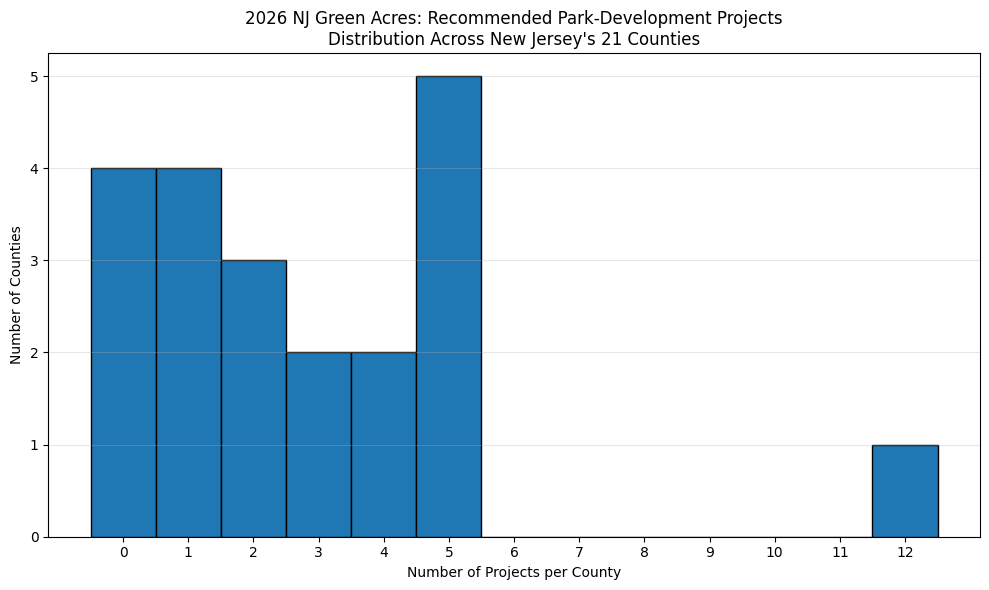

Histogram created successfully.
Counties with no projects: 4
Highest number of projects in one county: 12


In [55]:

# PS2 - Histogram of 2026 Green Acres projects

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

project_counts = ps2_county_map["Projects"]

plt.figure(figsize=(10, 6))

plt.hist(
    project_counts,
    bins=np.arange(-0.5, project_counts.max() + 1.5, 1),
    edgecolor="black"
)

plt.title(
    "2026 NJ Green Acres: Recommended Park-Development Projects\n"
    "Distribution Across New Jersey's 21 Counties"
)

plt.xlabel("Number of Projects per County")
plt.ylabel("Number of Counties")
plt.xticks(range(0, project_counts.max() + 1))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save the graph
output_folder = Path("/content/ps2_outputs")
output_folder.mkdir(exist_ok=True)

plt.savefig(
    output_folder / "PS2_Green_Acres_Histogram_2026.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Histogram created successfully.")
print("Counties with no projects:", (project_counts == 0).sum())
print("Highest number of projects in one county:", project_counts.max())


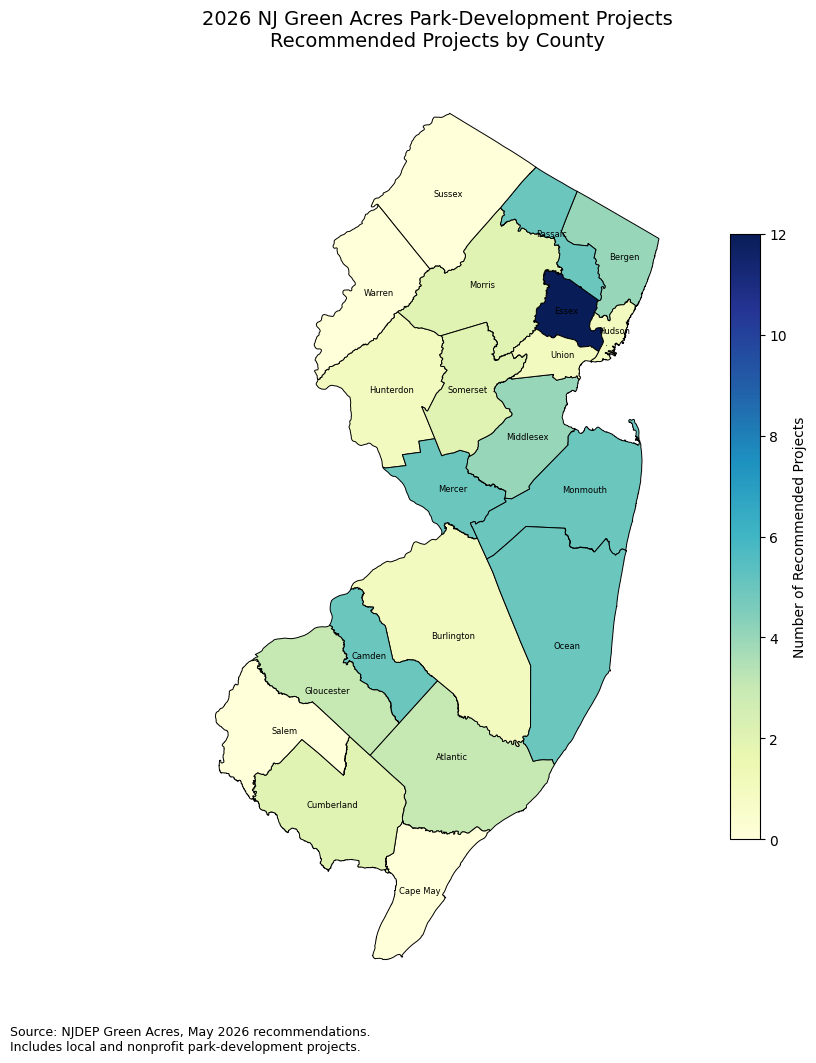

Green Acres county map created successfully!


In [56]:

# PS2 - Map Green Acres recommended projects by county

import matplotlib.pyplot as plt
from pathlib import Path

# Use New Jersey's map projection
map_data = ps2_county_map.to_crs(epsg=3424)

fig, ax = plt.subplots(figsize=(10, 11))

# Color counties by number of projects
map_data.plot(
    column="Projects",
    cmap="YlGnBu",
    edgecolor="black",
    linewidth=0.7,
    legend=True,
    legend_kwds={
        "label": "Number of Recommended Projects",
        "shrink": 0.65
    },
    ax=ax,
    vmin=0,
    vmax=12
)

# Label each county
for _, row in map_data.iterrows():
    point = row.geometry.representative_point()

    ax.text(
        point.x,
        point.y,
        row["County"],
        fontsize=6,
        ha="center",
        va="center"
    )

ax.set_title(
    "2026 NJ Green Acres Park-Development Projects\n"
    "Recommended Projects by County",
    fontsize=14,
    pad=18
)

ax.set_axis_off()

fig.text(
    0.12,
    0.04,
    "Source: NJDEP Green Acres, May 2026 recommendations.\n"
    "Includes local and nonprofit park-development projects.",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.07, 1, 1])

# Save the map
output_folder = Path("/content/ps2_outputs")
output_folder.mkdir(exist_ok=True)

plt.savefig(
    output_folder / "PS2_Green_Acres_County_Map_2026.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Green Acres county map created successfully!")


In [57]:

# PS2 - Compare Green Acres projects with youth football

import pandas as pd
import geopandas as gpd

# Load our previously verified youth football data
football_url = (
    "https://raw.githubusercontent.com/"
    "Dunk0725/GIS-26/NJ-Youth-Football-GIS/"
    "PS0_NJ_Youth_Football_Locations_2026.csv"
)

football = pd.read_csv(football_url)

# Exclude P181, which is awaiting organization verification
eligible = football.loc[
    football["Analysis_Eligibility"].str.startswith("Included")
].copy()

assert len(eligible) == 264

# Convert football locations into map points
football_points = gpd.GeoDataFrame(
    eligible,
    geometry=gpd.points_from_xy(
        eligible["Longitude"],
        eligible["Latitude"]
    ),
    crs="EPSG:4326"
)

# Match coordinate systems
football_points = football_points.to_crs(ps2_county_map.crs)

# Identify the county containing each home-field location
football_counties = gpd.sjoin(
    football_points,
    ps2_county_map[["County", "geometry"]],
    how="left",
    predicate="within"
)

assert len(football_counties) == 264
assert football_counties["County"].notna().all()

# Count youth football organizations in each county
football_counts = (
    football_counties.groupby("County")
    .size()
    .reset_index(name="Football_Organizations")
)

# Combine football counts with Green Acres project counts
ps2_comparison = (
    ps2_county_map[["County", "Projects"]]
    .merge(
        football_counts,
        on="County",
        how="left",
        validate="one_to_one"
    )
)

ps2_comparison["Football_Organizations"] = (
    ps2_comparison["Football_Organizations"]
    .fillna(0)
    .astype(int)
)

assert len(ps2_comparison) == 21
assert ps2_comparison["Football_Organizations"].sum() == 264

print("PS2 COUNTY COMPARISON")
print("Counties:", len(ps2_comparison))
print("Youth football organizations:",
      ps2_comparison["Football_Organizations"].sum())
print("Green Acres recommended projects:",
      ps2_comparison["Projects"].sum())

display(
    ps2_comparison.sort_values(
        "Projects",
        ascending=False
    ).reset_index(drop=True)
)


PS2 COUNTY COMPARISON
Counties: 21
Youth football organizations: 264
Green Acres recommended projects: 61


,County,Projects,Football_Organizations
0,Essex,12,18
1,Ocean,5,14
2,Monmouth,5,26
3,Mercer,5,6
4,Camden,5,18
5,Passaic,5,10
6,Middlesex,4,16
7,Bergen,4,36
8,Atlantic,3,13
9,Gloucester,3,13


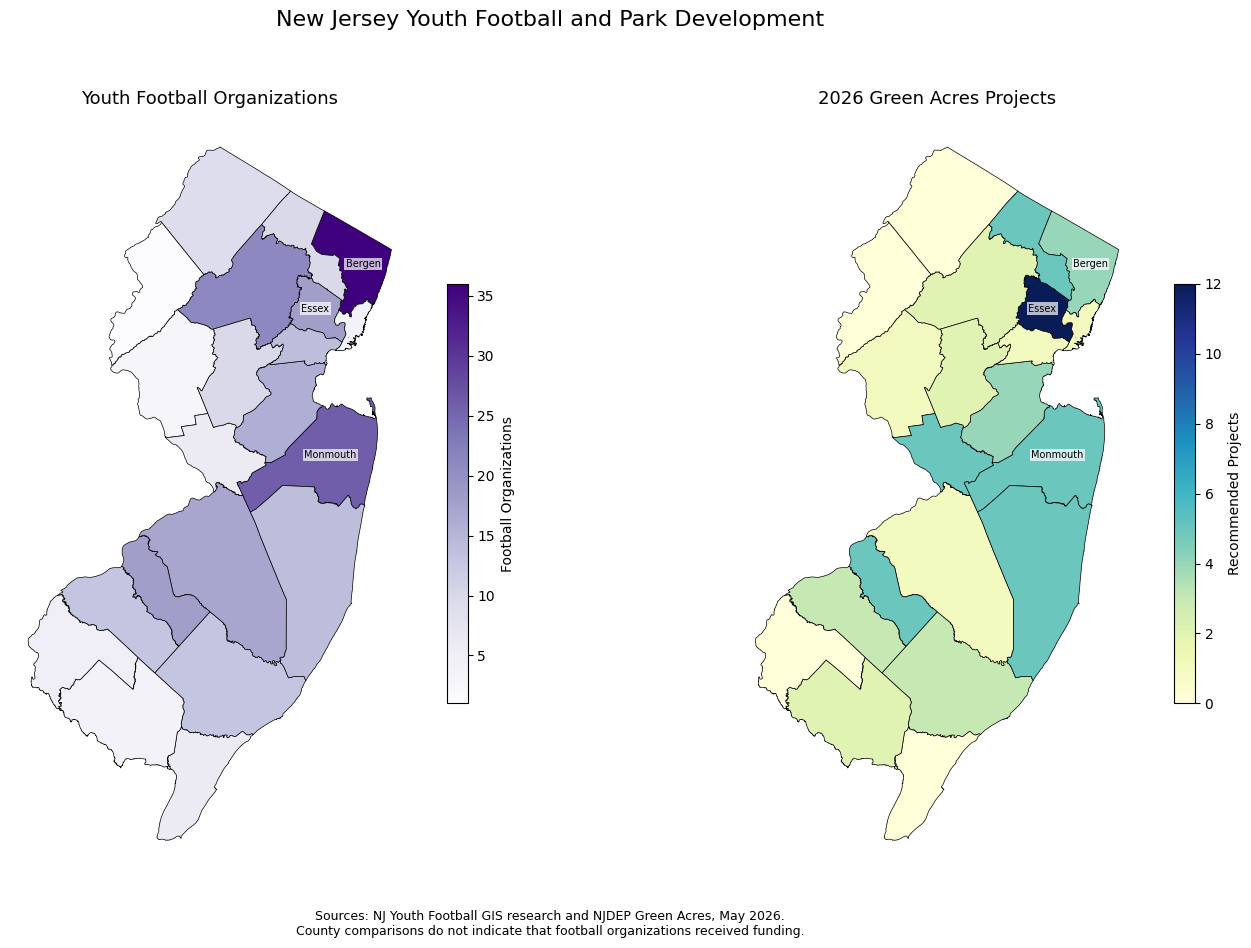

Side-by-side comparison created successfully.


In [58]:

# PS2 - Side-by-side comparison maps

import matplotlib.pyplot as plt
from pathlib import Path

# Add football counts to the existing county map
comparison_map = ps2_county_map[
    ["County", "Projects", "geometry"]
].merge(
    ps2_comparison[["County", "Football_Organizations"]],
    on="County",
    how="left",
    validate="one_to_one"
).to_crs(epsg=3424)

assert len(comparison_map) == 21
assert comparison_map["Football_Organizations"].sum() == 264
assert comparison_map["Projects"].sum() == 61

# Create two maps in one figure
fig, axes = plt.subplots(1, 2, figsize=(15, 10))

comparison_map.plot(
    column="Football_Organizations",
    cmap="Purples",
    edgecolor="black",
    linewidth=0.5,
    legend=True,
    legend_kwds={"label": "Football Organizations", "shrink": 0.55},
    ax=axes[0]
)

comparison_map.plot(
    column="Projects",
    cmap="YlGnBu",
    edgecolor="black",
    linewidth=0.5,
    legend=True,
    legend_kwds={"label": "Recommended Projects", "shrink": 0.55},
    ax=axes[1],
    vmin=0
)

axes[0].set_title("Youth Football Organizations", fontsize=13)
axes[1].set_title("2026 Green Acres Projects", fontsize=13)

for ax in axes:
    ax.set_axis_off()

    # Label counties discussed in our findings
    for _, row in comparison_map.iterrows():
        if row["County"] in ["Bergen", "Essex", "Monmouth"]:
            point = row.geometry.representative_point()
            ax.text(
                point.x, point.y, row["County"],
                fontsize=7, ha="center", va="center",
                bbox=dict(facecolor="white", alpha=0.7,
                          edgecolor="none", pad=1)
            )

fig.suptitle(
    "New Jersey Youth Football and Park Development",
    fontsize=16,
    y=0.97
)

fig.text(
    0.5, 0.045,
    "Sources: NJ Youth Football GIS research and NJDEP Green Acres, May 2026.\n"
    "County comparisons do not indicate that football organizations received funding.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.09, 1, 0.94])

output_folder = Path("/content/ps2_outputs")
output_folder.mkdir(exist_ok=True)

plt.savefig(
    output_folder / "PS2_Football_Green_Acres_Comparison_2026.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Side-by-side comparison created successfully.")


## 11. PS2 Findings and Interpretation

This analysis compares 264 New Jersey youth football organizations with 61 park-development projects recommended through NJDEP's 2026 Green Acres funding round.

The maps show that recreation resources are not distributed evenly across New Jersey. Essex County has 12 recommended projects and 18 youth football organizations. Bergen County has 36 youth football organizations but only 4 recommended projects.

Four counties have no projects in this particular funding category, even though they have youth football organizations.

These findings help identify places worth investigating for potential recreational partnerships. They may also inform future planning for the proposed New Jersey Youth and Amateur Sports Association (NJYASA).

**Important limitation:** These comparisons do not prove that youth football organizations received Green Acres funding or that counties with fewer projects have inadequate recreation resources. They show geographic patterns that deserve further research.